# Chapter 1 Hands-On Project: Vector Spaces, Inner Products, Regularization & Optimization Geometry

Welcome to the companion coding project for **Chapter 1: Vector Space and Inner Product** of *Mathematics for AI and Machine Learning* ([https://math4ai.org](https://math4ai.org)).

In this notebook, we bridge the abstract mathematical structures of Chapter 1 with practical **NumPy**, **Scikit-Learn**, and **PyTorch** implementations:

1. **Part 1 — Inner Products, Vector Projections & Hyperplane Geometry**:
   - Dot product, cosine similarity, Cauchy–Schwarz inequality, and orthogonal energy additivity ($\|\mathbf{u}+\mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2$).
   - Vector-vector projection via outer product operators $P = \frac{\mathbf{v}\mathbf{v}^\top}{\mathbf{v}^\top\mathbf{v}}$ and orthogonal decomposition $\mathbf{u} = \mathbf{p} + \mathbf{d}_\perp$.
   - Point-to-hyperplane distance: comparing **Linear Regression vertical residuals** ($r = y - \hat{y}$) against **SVM orthogonal geometric margins** ($d_\perp$).
2. **Part 2 — Norms Geometry ($\ell_p$, $\text{Std-}\ell_2$, Mahalanobis) & Anomaly Detection**:
   - Visualizing the unit balls of $\ell_1$, $\ell_2$, $\ell_4$, $\ell_\infty$, Standardized Euclidean ($\text{Std-}\ell_2$), and Mahalanobis ($\|\mathbf{v}\|_M = \sqrt{\mathbf{v}^\top \Sigma^{-1}\mathbf{v}}$) norms.
   - Practical **Out-of-Distribution (OOD) / Anomaly Detection** on correlated features where Euclidean distance fails and Mahalanobis distance succeeds.
3. **Part 3 — Hilbert vs. Banach Spaces in Practice: Ridge ($\ell_2$) vs. LASSO ($\ell_1$) Regularization**:
   - Testing the **Parallelogram Law** to see why $(\mathbb{R}^d, \|\cdot\|_2)$ is a Hilbert space while $(\mathbb{R}^d, \|\cdot\|_1)$ is only a Banach space.
   - Visualizing the geometric origin of sparsity ($\ell_1$ diamond corners vs. $\ell_2$ smooth circle).
   - **Hands-on Ridge & LASSO Regression** (both from scratch via Proximal Gradient Descent / ISTA and with `scikit-learn`): recovering sparse true weights in high-dimensional noisy data and plotting full **regularization paths**.
4. **Part 4 — Banach Space Completeness, Cauchy Sequences & Weight Decay (`SGD`, `Adam`, `AdamW`)**:
   - Matrix optimization in Banach space $(\mathbb{R}^{m\times n}, \|\cdot\|_F)$ and the **Weight Decay Quadratic Bowl** pull ($\mathbf{W}_{\text{opt}} = \frac{2}{2+\lambda}\mathbf{W}^*$).
   - **Counterexample**: Why constant-LR minibatch SGD decreases loss without forming a Cauchy sequence ($\|\mathbf{W}_{k+1}-\mathbf{W}_k\|_F \not\to 0$), and how learning-rate decay restores Cauchy convergence.
   - **PyTorch Deep Learning Practical**: Comparing Unregularized MLP, SGD + Weight Decay, Adam + coupled $\ell_2$ penalty, and **AdamW (Decoupled Weight Decay)**.
5. **Part 5 — Gram–Schmidt Orthonormalization & Scaled Dot-Product Attention in Hilbert Space**:
   - Constructing an orthonormal basis via Gram–Schmidt and implementing **Transformer Scaled Dot-Product Attention** ($\text{softmax}(QK^\top / \sqrt{d_k})V$), verifying why the $\frac{1}{\sqrt{d_k}}$ scaling prevents vanishing gradients.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from sklearn.linear_model import Ridge, Lasso

# Global plotting and reproducibility settings
np.random.seed(42)
torch.manual_seed(42)
plt.rcParams.update({
    "figure.dpi": 120,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "font.size": 10,
    "axes.titlesize": 11,
    "axes.labelsize": 10
})
print("Environment initialized successfully!")

Environment initialized successfully!


---
## Part 1: Inner Products, Vector Projections & Hyperplane Distance

### 1.1 Inner Product, Unit Vectors, Cauchy–Schwarz & Energy Additivity

For column vectors $\mathbf{u}, \mathbf{v} \in \mathbb{R}^d$, the standard inner product is:
$$\langle \mathbf{u}, \mathbf{v} \rangle = \mathbf{u}^\top \mathbf{v} = \sum_{i=0}^{d-1} u_i v_i = \|\mathbf{u}\|_2 \|\mathbf{v}\|_2 \cos\theta$$

Key theorems from Chapter 1:
- **Cauchy–Schwarz Inequality**: $|\langle \mathbf{u}, \mathbf{v} \rangle| \le \|\mathbf{u}\|_2 \|\mathbf{v}\|_2$, with equality iff $\mathbf{u}$ and $\mathbf{v}$ are collinear.
- **Triangle Inequality**: $\|\mathbf{u} + \mathbf{v}\|_2 \le \|\mathbf{u}\|_2 + \|\mathbf{v}\|_2$.
- **Energy Additivity (Pythagorean Theorem)**: $\|\mathbf{u} + \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2 + 2\langle \mathbf{u}, \mathbf{v} \rangle$. When $\mathbf{u} \perp \mathbf{v}$ ($\langle \mathbf{u}, \mathbf{v} \rangle = 0$), energy is strictly additive: $\|\mathbf{u} + \mathbf{v}\|_2^2 = \|\mathbf{u}\|_2^2 + \|\mathbf{v}\|_2^2$.

### 1.2 Vector-Vector Projection & Outer Product Matrix

Given $\mathbf{v} \in \mathbb{R}^d$ and target direction $\mathbf{x} \in \mathbb{R}^d$, the orthogonal projection of $\mathbf{v}$ onto $\mathbf{x}$ is:
$$\mathbf{p} = \frac{\langle \mathbf{v}, \mathbf{x} \rangle}{\|\mathbf{x}\|_2^2} \mathbf{x} = \underbrace{\left(\frac{\mathbf{x}\mathbf{x}^\top}{\mathbf{x}^\top \mathbf{x}}\right)}_{P_{\mathbf{x}}} \mathbf{v}, \qquad \mathbf{r}_{\perp} = \mathbf{v} - \mathbf{p}$$
where $P_{\mathbf{x}} = \frac{\mathbf{x}\mathbf{x}^\top}{\mathbf{x}^\top \mathbf{x}} \in \mathbb{R}^{d \times d}$ is the rank-1 **projection matrix** formed by the outer product $\mathbf{x}\mathbf{x}^\top$ divided by the inner product $\mathbf{x}^\top \mathbf{x}$ (`n / d` in matrix form).

In [2]:
# 1. Vector-Vector Projection via Outer Product (n = x x^T) and Inner Product (d = x^T x)
v = np.array([[1.0, 2.0, 3.0]]).T   # Target vector to project (3x1)
x = np.array([[2.0, 3.0, 1.0]]).T   # Direction vector (3x1)

n = x @ x.T                         # Outer product: 3x3 matrix
d = (x.T @ x).item()                # Inner product (squared L2 norm): scalar 14.0
P_x = n / d                         # Rank-1 Orthogonal Projection Matrix

p = P_x @ v                         # Projected vector p onto span(x)
r_perp = v - p                      # Orthogonal component v - p

print("Outer product matrix n = x x^T:\n", n)
print(f"Inner product scalar d = x^T x: {d:.1f}")
print(f"Projected vector p^T:           {p.ravel().round(6)}")
print(f"Orthogonal component r_perp^T:  {r_perp.ravel().round(6)}")

# Verify orthogonality <p, r_perp> == 0 and Energy Additivity ||v||_2^2 == ||p||_2^2 + ||r_perp||_2^2
inner_p_r = (p.T @ r_perp).item()
energy_v = np.linalg.norm(v) ** 2
energy_sum = np.linalg.norm(p) ** 2 + np.linalg.norm(r_perp) ** 2
print(f"\nVerification:")
print(f"  <p, r_perp> = {inner_p_r:.2e} (Orthogonal!)")
print(f"  ||v||_2^2 = {energy_v:.6f}  vs.  ||p||_2^2 + ||r_perp||_2^2 = {energy_sum:.6f}")
print(f"  Idempotency P_x^2 == P_x: {np.allclose(P_x @ P_x, P_x)}")

Outer product matrix n = x x^T:
 [[4. 6. 2.]
 [6. 9. 3.]
 [2. 3. 1.]]
Inner product scalar d = x^T x: 14.0
Projected vector p^T:           [1.571429 2.357143 0.785714]
Orthogonal component r_perp^T:  [-0.571429 -0.357143  2.214286]

Verification:
  <p, r_perp> = 0.00e+00 (Orthogonal!)
  ||v||_2^2 = 14.000000  vs.  ||p||_2^2 + ||r_perp||_2^2 = 14.000000
  Idempotency P_x^2 == P_x: True


### 1.3 Point-to-Hyperplane Distance: Regression Residual ($r$) vs. Orthogonal Distance ($d_\perp$)

In Section *"Example: Orthogonal Distance from Point to Hyperplane"* of Chapter 1:
- A hyperplane in $\mathbb{R}^d$ is defined by $\boldsymbol{\theta}^\top \mathbf{x} = b$. The signed orthogonal distance from a point $\mathbf{u} \in \mathbb{R}^d$ to the hyperplane is:
  $$d_{\perp} = \frac{\boldsymbol{\theta}^\top \mathbf{u} - b}{\|\boldsymbol{\theta}\|_2}$$
- In **Linear Regression**, $\hat{y} = \boldsymbol{\theta}^\top \mathbf{x} + b$ defines a hyperplane $\boldsymbol{\theta}^\top \mathbf{x} - y + b = 0$ in the augmented space $(\mathbf{x}, y) \in \mathbb{R}^{d+1}$ with normal vector $\tilde{\boldsymbol{\theta}} = [\boldsymbol{\theta}^\top, -1]^\top$.
- For the Chapter 1 example $\boldsymbol{\theta} = [2, -1]^\top$, $b = 5$, and data point $\mathbf{x} = [1, 2]^\top, y = 3$:
  - **Prediction**: $\hat{y} = 2(1) - 1(2) + 5 = 5$
  - **Vertical Prediction Residual**: $r = y - \hat{y} = 3 - 5 = -2$ (minimized by Least Squares)
  - **Orthogonal Geometric Distance**: $|d_{\perp}| = \frac{|r|}{\sqrt{\|\boldsymbol{\theta}\|_2^2 + 1}} = \frac{2}{\sqrt{6}} \approx 0.8165$ (optimized by Support Vector Machines)

Predicted y_hat:             5.0000
Prediction Residual r:       -2.0000
Orthogonal Distance |d_perp|: 0.816497  (2/sqrt(6) = 0.816497)


<>:28: SyntaxWarning: invalid escape sequence '\h'
<>:28: SyntaxWarning: invalid escape sequence '\h'
/tmp/ipykernel_1225980/2465117935.py:28: SyntaxWarning: invalid escape sequence '\h'
  ax.scatter([x_pt[0]], [y_hat], color="#2ca02c", s=80, zorder=5, label=f"Predicted Point $(x_0=1, \hat{{y}}=5)$")


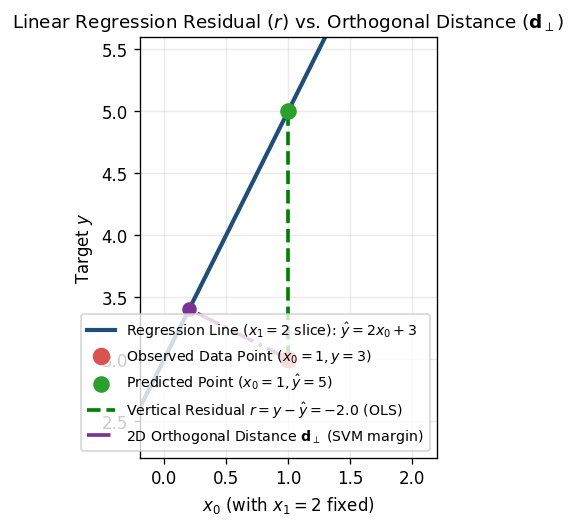

In [3]:
# Verify the exact Chapter 1 numerical example
theta = np.array([2.0, -1.0])
b = 5.0
x_pt = np.array([1.0, 2.0])
y_pt = 3.0

y_hat = theta @ x_pt + b
residual_r = y_pt - y_hat

# Augmented space normal vector: tilde_theta = [theta_0, theta_1, -1]^T, offset = -b
tilde_theta = np.append(theta, -1.0)
u_aug = np.append(x_pt, y_pt)
d_perp = (tilde_theta @ u_aug + b) / np.linalg.norm(tilde_theta)

print(f"Predicted y_hat:             {y_hat:.4f}")
print(f"Prediction Residual r:       {residual_r:.4f}")
print(f"Orthogonal Distance |d_perp|: {abs(d_perp):.6f}  (2/sqrt(6) = {2/np.sqrt(6):.6f})")

# 2D cross-section visualization (fixing x_1 = 2, varying x_0)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
x0_vals = np.linspace(-0.5, 2.5, 200)
x1_fixed = 2.0
# Line in 2D slice (x_0, y) when x_1 = 2: y = 2*x_0 - 2 + 5 = 2*x_0 + 3
y_line = theta[0] * x0_vals + theta[1] * x1_fixed + b

ax.plot(x0_vals, y_line, color="#1f4e78", lw=2.5, label=r"Regression Line ($x_1=2$ slice): $\hat{y} = 2x_0 + 3$")
ax.scatter([x_pt[0]], [y_pt], color="#d9534f", s=90, zorder=5, label=f"Observed Data Point $(x_0=1, y=3)$")
ax.scatter([x_pt[0]], [y_hat], color="#2ca02c", s=80, zorder=5, label=f"Predicted Point $(x_0=1, \hat{{y}}=5)$")

# Vertical residual r (green dashed)
ax.plot([x_pt[0], x_pt[0]], [y_pt, y_hat], "g--", lw=2.2, label=f"Vertical Residual $r = y - \\hat{{y}} = {residual_r:.1f}$ (OLS)")

# Orthogonal foot in 2D slice: line is 2*x_0 - y + 3 = 0, normal n_2d = [2, -1]
n_2d = np.array([theta[0], -1.0])
pt_2d = np.array([x_pt[0], y_pt])
foot_2d = pt_2d - ((n_2d @ pt_2d + 3.0) / (n_2d @ n_2d)) * n_2d
ax.plot([pt_2d[0], foot_2d[0]], [pt_2d[1], foot_2d[1]], color="#7b3294", ls="-.", lw=2.2,
        label=r"2D Orthogonal Distance $\mathbf{d}_{\perp}$ (SVM margin)")
ax.scatter([foot_2d[0]], [foot_2d[1]], color="#7b3294", s=60, zorder=5)

ax.set_aspect("equal")
ax.set_xlim(-0.2, 2.2)
ax.set_ylim(2.2, 5.6)
ax.set_xlabel("$x_0$ (with $x_1 = 2$ fixed)")
ax.set_ylabel("Target $y$")
ax.set_title("Linear Regression Residual ($r$) vs. Orthogonal Distance ($\\mathbf{d}_{\\perp}$)")
ax.legend(loc="lower right", fontsize=8.5)
plt.tight_layout()
plt.show()

---
## Part 2: Norms Geometry ($\ell_p$, $\text{Std-}\ell_2$, Mahalanobis) & Anomaly Detection

### 2.1 Visualizing the 6 Unit Balls from Chapter 1

In Section *"Norms"*, Chapter 1 defines six fundamental norms on $\mathbb{R}^d$:
1. **Manhattan ($\ell_1$)**: $\|\mathbf{v}\|_1 = \sum_{i} |v_i|$ (diamond unit ball — sharp corners on axes)
2. **Euclidean ($\ell_2$)**: $\|\mathbf{v}\|_2 = \sqrt{\sum_i v_i^2}$ (circular unit ball — isotropic)
3. **Minkowski ($\ell_4$)**: $\|\mathbf{v}\|_4 = \left(\sum_i |v_i|^4\right)^{1/4}$ (rounded square / squircle)
4. **Chebyshev ($\ell_\infty$)**: $\|\mathbf{v}\|_\infty = \max_i |v_i|$ (axis-aligned square)
5. **Standardized Euclidean ($\text{Std-}\ell_2$)**: $\|\mathbf{v}\|_{\text{Std-}\ell_2} = \sqrt{\sum_i (v_i / \sigma_i)^2}$ (axis-aligned ellipse — implicit geometry of **Adam/RMSProp** and **BatchNorm/LayerNorm**)
6. **Mahalanobis Norm (M-norm)**: $\|\mathbf{v}\|_M = \sqrt{\mathbf{v}^\top \Sigma^{-1} \mathbf{v}}$ (rotated ellipse — accounts for feature correlations; implicit geometry of **Natural Gradient / Shampoo / Muon** and **OOD detection**).

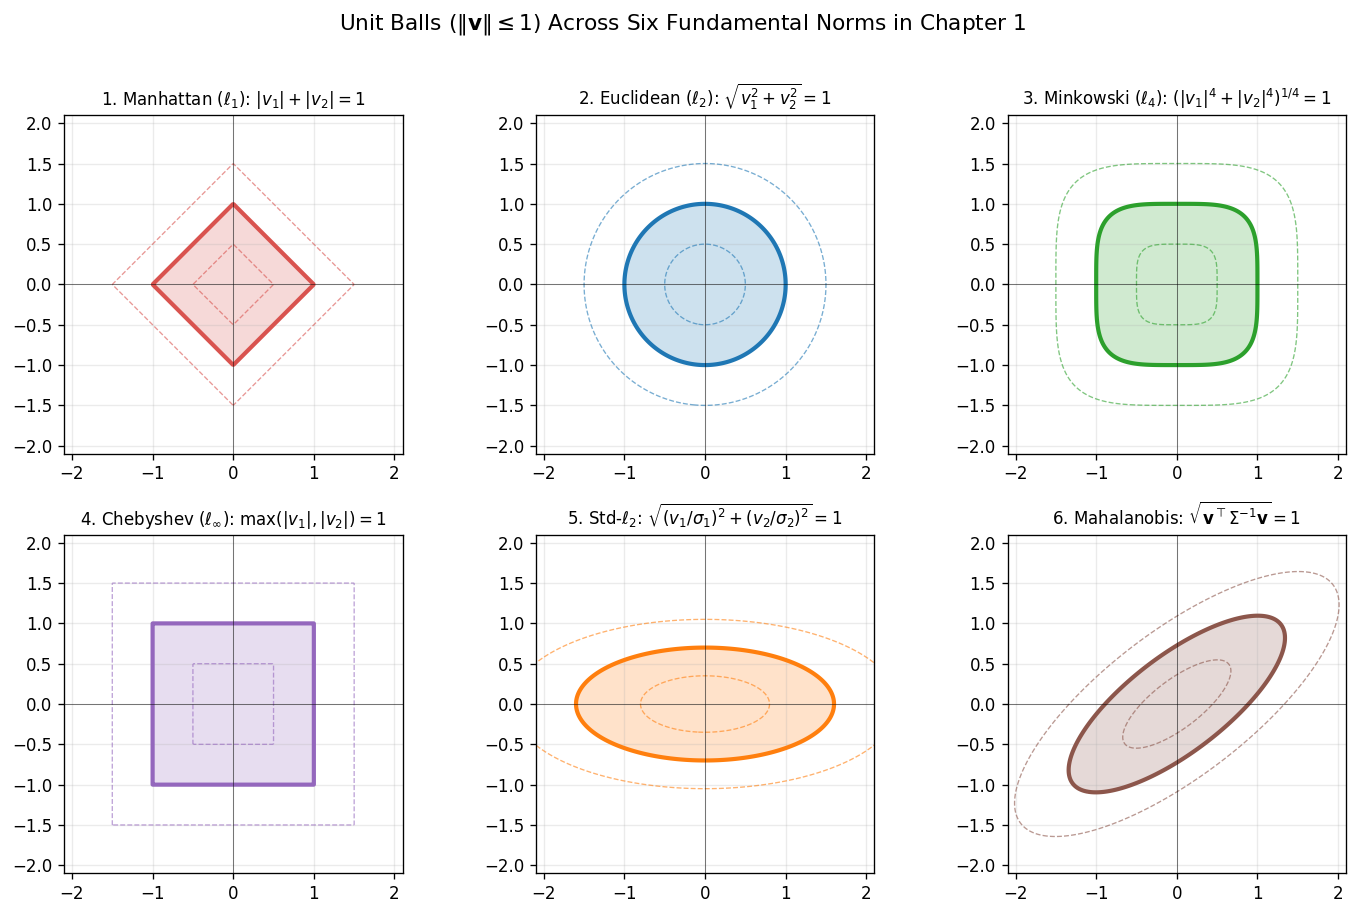

In [4]:
# Plot the unit balls {v in R^2 : ||v|| = 1} for all 6 norms
grid = np.linspace(-2.2, 2.2, 400)
V1, V2 = np.meshgrid(grid, grid)
pts = np.stack([V1, V2], axis=-1)

# Covariance matrix Sigma for Mahalanobis and scales sigma for Std-L2
Sigma = np.array([[1.8, 1.1],
                  [1.1, 1.2]])
Sigma_inv = np.linalg.inv(Sigma)
sigma_scales = np.array([1.6, 0.7])

norms_dict = {
    r"1. Manhattan ($\ell_1$): $|v_1| + |v_2| = 1$": np.abs(V1) + np.abs(V2),
    r"2. Euclidean ($\ell_2$): $\sqrt{v_1^2 + v_2^2} = 1$": np.sqrt(V1**2 + V2**2),
    r"3. Minkowski ($\ell_4$): $(|v_1|^4 + |v_2|^4)^{1/4} = 1$": (np.abs(V1)**4 + np.abs(V2)**4)**0.25,
    r"4. Chebyshev ($\ell_\infty$): $\max(|v_1|, |v_2|) = 1$": np.maximum(np.abs(V1), np.abs(V2)),
    r"5. Std-$\ell_2$: $\sqrt{(v_1/\sigma_1)^2 + (v_2/\sigma_2)^2} = 1$": np.sqrt((V1/sigma_scales[0])**2 + (V2/sigma_scales[1])**2),
    r"6. Mahalanobis: $\sqrt{\mathbf{v}^\top \Sigma^{-1}\mathbf{v}} = 1$": np.sqrt(
         np.einsum("...i,ij,...j->...", pts, Sigma_inv, pts)
    ),
}

fig, axes = plt.subplots(2, 3, figsize=(12, 7.5))
colors = ["#d9534f", "#1f77b4", "#2ca02c", "#9467bd", "#ff7f0e", "#8c564b"]

for ax, (title, Z), col in zip(axes.ravel(), norms_dict.items(), colors):
    ax.contourf(V1, V2, Z, levels=[0, 1.0], colors=[col], alpha=0.22)
    ax.contour(V1, V2, Z, levels=[1.0], colors=[col], linewidths=2.5)
    ax.contour(V1, V2, Z, levels=[0.5, 1.5], colors=[col], linewidths=0.8, linestyles="--", alpha=0.6)
    ax.axhline(0, color="k", lw=0.6, alpha=0.5)
    ax.axvline(0, color="k", lw=0.6, alpha=0.5)
    ax.set_aspect("equal")
    ax.set_title(title, fontsize=10)
    ax.set_xlim(-2.1, 2.1)
    ax.set_ylim(-2.1, 2.1)

plt.suptitle("Unit Balls ($\\|\\mathbf{v}\\| \\leq 1$) Across Six Fundamental Norms in Chapter 1", fontsize=13, y=1.01)
plt.tight_layout()
plt.show()

### 2.2 Practical Application: Anomaly / OOD Detection with Mahalanobis vs. Euclidean Distance

Why does Chapter 1 emphasize **Mahalanobis distance** $\|\mathbf{x} - \boldsymbol{\mu}\|_M = \sqrt{(\mathbf{x}-\boldsymbol{\mu})^\top \Sigma^{-1} (\mathbf{x}-\boldsymbol{\mu})}$?

Suppose we monitor two strongly correlated features (e.g., server CPU load and power consumption). Consider two test points at the **exact same Euclidean distance** $\|\mathbf{x} - \boldsymbol{\mu}\|_2 = 3.0$ from the mean:
- **Point A** lies *along* the natural correlation axis (normal high-traffic behavior).
- **Point B** lies *orthogonal* to the correlation axis (e.g., high power consumption with low CPU load — a hardware fault or anomaly!).

Euclidean distance treats Point A and Point B identically, whereas Mahalanobis distance immediately flags Point B as a severe outlier.

Point A (Along correlation)      -> Euclidean: 2.979 | Mahalanobis: 1.561
Point B (Off-axis OOD Anomaly)   -> Euclidean: 3.007 | Mahalanobis: 6.957


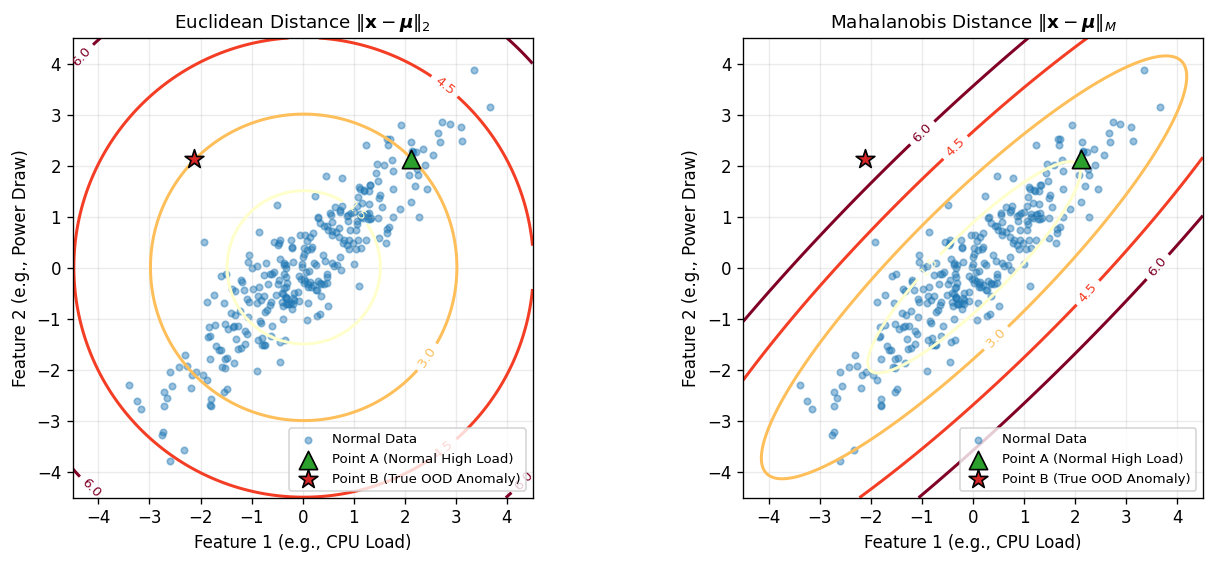

In [5]:
# Simulate correlated normal training data in R^2
cov_true = np.array([[2.0, 1.8],
                     [1.8, 2.0]])
mean_true = np.array([0.0, 0.0])
X_train_norm = np.random.multivariate_normal(mean_true, cov_true, size=300)

# Estimate sample mean and covariance
mu_hat = X_train_norm.mean(axis=0)
Sigma_hat = np.cov(X_train_norm, rowvar=False)
Sigma_hat_inv = np.linalg.inv(Sigma_hat)

# Construct two test points with the EXACT SAME Euclidean distance (3.0) from the origin:
# Point A: along the principal correlation diagonal [1, 1]/sqrt(2)
# Point B: orthogonal to the correlation diagonal [-1, 1]/sqrt(2)
dist_euclid = 3.0
pt_A = dist_euclid * np.array([1.0, 1.0]) / np.sqrt(2)     # In-distribution high load
pt_B = dist_euclid * np.array([-1.0, 1.0]) / np.sqrt(2)    # Out-of-distribution anomaly!

def mahalanobis_dist(x, mu, cov_inv):
    diff = x - mu
    return float(np.sqrt(diff.T @ cov_inv @ diff))

print(f"Point A (Along correlation)      -> Euclidean: {np.linalg.norm(pt_A - mu_hat):.3f} | Mahalanobis: {mahalanobis_dist(pt_A, mu_hat, Sigma_hat_inv):.3f}")
print(f"Point B (Off-axis OOD Anomaly)   -> Euclidean: {np.linalg.norm(pt_B - mu_hat):.3f} | Mahalanobis: {mahalanobis_dist(pt_B, mu_hat, Sigma_hat_inv):.3f}")

# Visualize Euclidean vs Mahalanobis contours
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8))
gx = np.linspace(-4.5, 4.5, 250)
GX, GY = np.meshgrid(gx, gx)
grid_pts = np.stack([GX - mu_hat[0], GY - mu_hat[1]], axis=-1)

Z_euclid = np.sqrt(grid_pts[..., 0]**2 + grid_pts[..., 1]**2)
Z_mahal = np.sqrt(np.einsum("...i,ij,...j->...", grid_pts, Sigma_hat_inv, grid_pts))

for ax, Z, name in zip(axes, [Z_euclid, Z_mahal], ["Euclidean Distance $\\|\\mathbf{x}-\\boldsymbol{\\mu}\\|_2$", "Mahalanobis Distance $\\|\\mathbf{x}-\\boldsymbol{\\mu}\\|_M$"]):
    ax.scatter(X_train_norm[:, 0], X_train_norm[:, 1], s=15, alpha=0.45, color="#1f77b4", label="Normal Data")
    cs = ax.contour(GX, GY, Z, levels=[1.5, 3.0, 4.5, 6.0], cmap="YlOrRd", linewidths=1.8)
    ax.clabel(cs, inline=True, fontsize=8, fmt="%.1f")
    ax.scatter(*pt_A, color="#2ca02c", s=120, marker="^", edgecolors="k", zorder=6, label="Point A (Normal High Load)")
    ax.scatter(*pt_B, color="#d62728", s=140, marker="*", edgecolors="k", zorder=6, label="Point B (True OOD Anomaly)")
    ax.set_aspect("equal")
    ax.set_xlim(-4.5, 4.5)
    ax.set_ylim(-4.5, 4.5)
    ax.set_title(name)
    ax.set_xlabel("Feature 1 (e.g., CPU Load)")
    ax.set_ylabel("Feature 2 (e.g., Power Draw)")
    ax.legend(loc="lower right", fontsize=8)

plt.tight_layout()
plt.show()

---
## Part 3: Hilbert vs. Banach Spaces in Practice — Ridge ($\ell_2$) vs. LASSO ($\ell_1$) Regularization

### 3.1 Why $(\mathbb{R}^d, \|\cdot\|_2)$ is a Hilbert Space while $(\mathbb{R}^d, \|\cdot\|_1)$ is Only a Banach Space

In Section *"Hilbert Space — Counterexample: $\ell_1$ Norm and LASSO Regularization"*, Chapter 1 shows that a norm is induced by an inner product **if and only if** it satisfies the **Parallelogram Law**:
$$\|\mathbf{u} + \mathbf{v}\|^2 + \|\mathbf{u} - \mathbf{v}\|^2 = 2\|\mathbf{u}\|^2 + 2\|\mathbf{v}\|^2 \quad \forall \mathbf{u}, \mathbf{v} \in \mathbb{R}^d$$

- **Ridge Regression ($\ell_2$ penalty)** operates in a **Hilbert space**:
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \frac{\lambda}{2}\|\boldsymbol{\theta}\|_2^2$$
  Its unit ball is smooth and isotropic, yielding a closed-form inner-product solution and **dense** parameter shrinkage.
- **LASSO Regression ($\ell_1$ penalty)** operates in a **Banach space** (not a Hilbert space):
  $$\min_{\boldsymbol{\theta}} \; \frac{1}{2N}\|X\boldsymbol{\theta} - \mathbf{y}\|_2^2 + \lambda\|\boldsymbol{\theta}\|_1$$
  Because the $\ell_1$ unit ball has **sharp corners along the coordinate axes**, expanding loss contours almost always touch a corner first, driving irrelevant weights to **exact zero (sparsity)**!

In [6]:
# 1. Numerical Verification of the Parallelogram Law for L2 (Hilbert) vs L1 (Banach only)
u_test = np.array([1.0, 0.0])
v_test = np.array([0.0, 1.0])

for p_norm, space_type in [(2, "Hilbert Space (L2)"), (1, "Banach Space ONLY (L1)")]:
    lhs = np.linalg.norm(u_test + v_test, ord=p_norm)**2 + np.linalg.norm(u_test - v_test, ord=p_norm)**2
    rhs = 2 * (np.linalg.norm(u_test, ord=p_norm)**2 + np.linalg.norm(v_test, ord=p_norm)**2)
    print(f"{space_type:24s} -> LHS = {lhs:.2f}, RHS = {rhs:.2f} | Parallelogram Law Holds? {np.isclose(lhs, rhs)}")

Hilbert Space (L2)       -> LHS = 4.00, RHS = 4.00 | Parallelogram Law Holds? True
Banach Space ONLY (L1)   -> LHS = 8.00, RHS = 4.00 | Parallelogram Law Holds? False


### 3.2 Implementing Ridge & LASSO From Scratch + Regularization Paths

Let's implement both algorithms **from scratch** and compare them on a high-dimensional sparse feature selection task:
- **Setup**: $N = 120$ samples, $d = 40$ features. Only **5 features** are truly active ($\boldsymbol{\theta}^* = [3.5, -2.8, 2.0, -1.5, 1.2, 0, \ldots, 0]^\top$), while the remaining 35 features are pure noise!
- **Ridge Closed-Form Solution**:
  $$\hat{\boldsymbol{\theta}}_{\text{Ridge}}(\lambda) = (X^\top X + N\lambda I)^{-1} X^\top \mathbf{y}$$
- **LASSO Proximal Gradient Descent (ISTA — Iterative Soft-Thresholding Algorithm)**:
  Each step takes a gradient step on the smooth MSE loss followed by the $\ell_1$ **proximal operator (soft-thresholding)** $\mathcal{S}_{\eta\lambda}$:
  $$\boldsymbol{\theta}^{(k+1)} = \mathcal{S}_{\eta\lambda}\!\left(\boldsymbol{\theta}^{(k)} - \frac{\eta}{N} X^\top (X\boldsymbol{\theta}^{(k)} - \mathbf{y})\right), \quad \text{where } [\mathcal{S}_{\tau}(\mathbf{z})]_i = \operatorname{sign}(z_i)\max(|z_i| - \tau, 0)$$
  Notice how soft-thresholding $\max(|z_i| - \tau, 0)$ creates an exact **dead-zone** $[-\tau, \tau]$ that snaps small coefficients to `0.0`!

In [7]:
# Generate synthetic high-dimensional sparse regression dataset
np.random.seed(42)
N_samples, d_features = 120, 40
X_raw = np.random.randn(N_samples, d_features)
# Standardize features (Z-score normalization from Chapter 1)
X_data = (X_raw - X_raw.mean(axis=0)) / X_raw.std(axis=0)

# True sparse weight vector: only first 5 features are non-zero!
theta_true = np.zeros(d_features)
active_indices = [0, 1, 2, 3, 4]
theta_true[active_indices] = [3.5, -2.8, 2.0, -1.5, 1.2]

# Generate noisy targets y = X @ theta_true + noise
y_data = X_data @ theta_true + 0.5 * np.random.randn(N_samples)

# Split into train (80) and test (40)
X_tr, X_te = X_data[:80], X_data[80:]
y_tr, y_te = y_data[:80], y_data[80:]

# --- 1. From-Scratch Ridge Solver ---
def fit_ridge_scratch(X, y, lam):
    N, d = X.shape
    return np.linalg.solve(X.T @ X + N * lam * np.eye(d), X.T @ y)

# --- 2. From-Scratch LASSO Solver (ISTA Soft-Thresholding) ---
def soft_threshold(z, tau):
    return np.sign(z) * np.maximum(np.abs(z) - tau, 0.0)

def fit_lasso_ista(X, y, lam, max_iter=1500, tol=1e-7):
    N, d = X.shape
    # Lipschitz constant of (1/N) X^T X is largest eigenvalue / N
    L = np.linalg.norm(X, ord=2) ** 2 / N
    eta = 1.0 / L
    theta = np.zeros(d)
    for _ in range(max_iter):
        grad = (X.T @ (X @ theta - y)) / N
        theta_next = soft_threshold(theta - eta * grad, eta * lam)
        if np.linalg.norm(theta_next - theta) < tol:
            theta = theta_next
            break
        theta = theta_next
    return theta

# Fit at lambda = 0.18 and compare with scikit-learn
lam_demo = 0.18
theta_ols = fit_ridge_scratch(X_tr, y_tr, lam=1e-8)
theta_ridge = fit_ridge_scratch(X_tr, y_tr, lam=lam_demo)
theta_lasso = fit_lasso_ista(X_tr, y_tr, lam=lam_demo)

# Verify against scikit-learn Lasso
sk_lasso = Lasso(alpha=lam_demo, fit_intercept=False, max_iter=5000).fit(X_tr, y_tr)
print(f"Max difference between our ISTA LASSO and sklearn Lasso: {np.max(np.abs(theta_lasso - sk_lasso.coef_)):.2e}")

# Evaluate sparsity & Test MSE
for name, w in [("Unregularized OLS", theta_ols), ("Ridge (L2, Hilbert)", theta_ridge), ("LASSO (L1, Banach)", theta_lasso)]:
    test_mse = np.mean((X_te @ w - y_te) ** 2)
    num_zeros = np.sum(np.abs(w) < 1e-4)
    print(f"{name:22s} | Test MSE: {test_mse:.4f} | Exact Zero Weights: {num_zeros:2d} / {d_features} (True zeros: 35)")

Max difference between our ISTA LASSO and sklearn Lasso: 5.65e-06
Unregularized OLS      | Test MSE: 0.4424 | Exact Zero Weights:  0 / 40 (True zeros: 35)
Ridge (L2, Hilbert)    | Test MSE: 3.2856 | Exact Zero Weights:  0 / 40 (True zeros: 35)
LASSO (L1, Banach)     | Test MSE: 0.3683 | Exact Zero Weights: 35 / 40 (True zeros: 35)


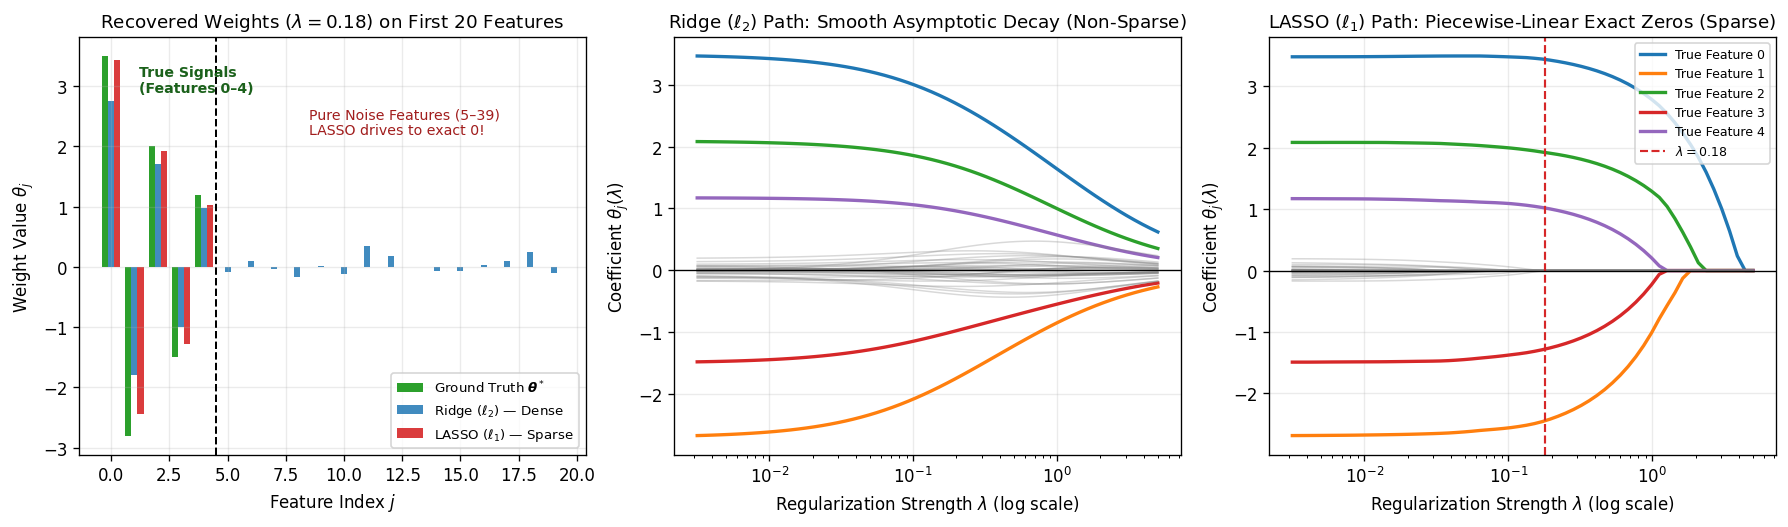

In [8]:
# Compute full Regularization Paths across a grid of lambda values
lambdas = np.logspace(-2.5, 0.7, 60)
ridge_path = np.array([fit_ridge_scratch(X_tr, y_tr, lam) for lam in lambdas])
lasso_path = np.array([fit_lasso_ista(X_tr, y_tr, lam) for lam in lambdas])

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Panel 1: Learned Weights Comparison at lambda = 0.18
ax = axes[0]
idx = np.arange(20)  # Plot first 20 features (0..4 are true signals, 5..19 are noise)
width = 0.26
ax.bar(idx - width, theta_true[:20], width=width, color="#2ca02c", label="Ground Truth $\\boldsymbol{\\theta}^*$" )
ax.bar(idx, theta_ridge[:20], width=width, color="#1f77b4", alpha=0.85, label="Ridge ($\\ell_2$) — Dense")
ax.bar(idx + width, theta_lasso[:20], width=width, color="#d62728", alpha=0.9, label="LASSO ($\\ell_1$) — Sparse")
ax.axvline(4.5, color="k", ls="--", lw=1.2)
ax.text(1.2, 2.9, "True Signals\n(Features 0–4)", fontsize=8.5, fontweight="bold", color="#1b611b")
ax.text(8.5, 2.2, "Pure Noise Features (5–39)\nLASSO drives to exact 0!", fontsize=8.5, color="#a11d1d")
ax.set_xlabel("Feature Index $j$")
ax.set_ylabel("Weight Value $\\theta_j$")
ax.set_title(f"Recovered Weights ($\\lambda={lam_demo}$) on First 20 Features")
ax.legend(fontsize=8, loc="lower right")

# Panel 2: Ridge Regularization Path
ax = axes[1]
for j in range(d_features):
    if j in active_indices:
        ax.plot(lambdas, ridge_path[:, j], lw=2.0, label=f"True Feature {j}" if j < 3 else None)
    else:
        ax.plot(lambdas, ridge_path[:, j], color="gray", alpha=0.3, lw=0.9)
ax.set_xscale("log")
ax.set_xlabel("Regularization Strength $\\lambda$ (log scale)")
ax.set_ylabel("Coefficient $\\theta_j(\\lambda)$")
ax.set_title("Ridge ($\\ell_2$) Path: Smooth Asymptotic Decay (Non-Sparse)")
ax.axhline(0, color="k", lw=0.8)

# Panel 3: LASSO Regularization Path
ax = axes[2]
for j in range(d_features):
    if j in active_indices:
        ax.plot(lambdas, lasso_path[:, j], lw=2.0, label=f"True Feature {j}")
    else:
        ax.plot(lambdas, lasso_path[:, j], color="gray", alpha=0.3, lw=0.9)
ax.axvline(lam_demo, color="#d62728", ls="--", lw=1.3, label=f"$\\lambda = {lam_demo}$")
ax.set_xscale("log")
ax.set_xlabel("Regularization Strength $\\lambda$ (log scale)")
ax.set_ylabel("Coefficient $\\theta_j(\\lambda)$")
ax.set_title("LASSO ($\\ell_1$) Path: Piecewise-Linear Exact Zeros (Sparse)")
ax.axhline(0, color="k", lw=0.8)
ax.legend(fontsize=7.5, loc="upper right")

plt.tight_layout()
plt.show()

---
## Part 4: Banach Space Completeness, Cauchy Sequences & Weight Decay in Deep Learning

### 4.1 Weight Matrix Space as a Banach Space & The Weight Decay "Quadratic Bowl"

In Section *"Example: Weight Matrix Space as a Banach Space"*, Chapter 1 models neural network training as a sequence of weight matrices $\{\mathbf{W}_k\}_{k=0}^\infty$ in the Banach space $(\mathbb{R}^{m \times n}, \|\cdot\|_F)$ equipped with the Frobenius norm $\|\mathbf{W}\|_F = \sqrt{\sum_{i,j} W_{ij}^2}$.

Consider minimizing the quadratic loss around $\mathbf{W}^* = \begin{bmatrix} 1.0 & -2.0 \\ 0.5 & 3.0 \end{bmatrix}$ starting from $\mathbf{W}_0 = \begin{bmatrix} 5.0 & 5.0 \\ -4.0 & -3.0 \end{bmatrix}$:
- **Without Weight Decay ($\lambda = 0$)**:
  $$\mathcal{L}(\mathbf{W}) = \|\mathbf{W} - \mathbf{W}^*\|_F^2 \implies \mathbf{W}_{k+1} = \mathbf{W}_k - 2\eta(\mathbf{W}_k - \mathbf{W}^*)$$
  The sequence $\{\mathbf{W}_k\}$ is a **Cauchy sequence** ($\|\mathbf{W}_{k+1} - \mathbf{W}_k\|_F \to 0$) and converges to $\mathbf{W}^*$.
- **With $\ell_2$ Weight Decay ($\lambda > 0$)**:
  $$\mathcal{L}_{\text{WD}}(\mathbf{W}) = \|\mathbf{W} - \mathbf{W}^*\|_F^2 + \frac{\lambda}{2}\|\mathbf{W}\|_F^2 \implies \mathbf{W}_{k+1} = \mathbf{W}_k - 2\eta(\mathbf{W}_k - \mathbf{W}^*) - \eta\lambda \mathbf{W}_k$$
  Weight decay adds a radial potential field $V(\mathbf{W}) = \frac{\lambda}{2}\|\mathbf{W}\|_F^2$ ("quadratic bowl") that pulls the converged limit inward toward the origin:
  $$\mathbf{W}_{\text{opt}} = \frac{2}{2 + \lambda} \mathbf{W}^*$$

### 4.2 Counterexample: Stochastic Gradient Noise — Loss Decreases but Sequence is NOT Cauchy!

When training with minibatch SGD under a **constant learning rate** $\eta$ and stochastic gradient noise $\boldsymbol{\epsilon}_k$:
$$\mathbf{W}_{k+1} = \mathbf{W}_k - \eta\big(2(\mathbf{W}_k - \mathbf{W}^*) + \boldsymbol{\epsilon}_k\big)$$
Even after the loss plateaus near its minimum, consecutive step sizes $\|\mathbf{W}_{k+1} - \mathbf{W}_k\|_F \approx \eta \|\boldsymbol{\epsilon}_k\|_F \not\to 0$. Thus $\{\mathbf{W}_k\}$ is **not Cauchy** and wanders perpetually in a noise ball around $\mathbf{W}^*$ unless we decay the learning rate ($\eta_k \to 0$).

Converged W (Standard GD):
 [[ 1.  -2. ]
 [ 0.5  3. ]]
Converged W (With Weight Decay lambda=0.5):
 [[ 0.8 -1.6]
 [ 0.4  2.4]]
Theoretical Shifted Optimum W_opt = (2/(2+lambda))*W^*:
 [[ 0.8 -1.6]
 [ 0.4  2.4]]
Max error between converged WD matrix and W_opt: 1.17e-07


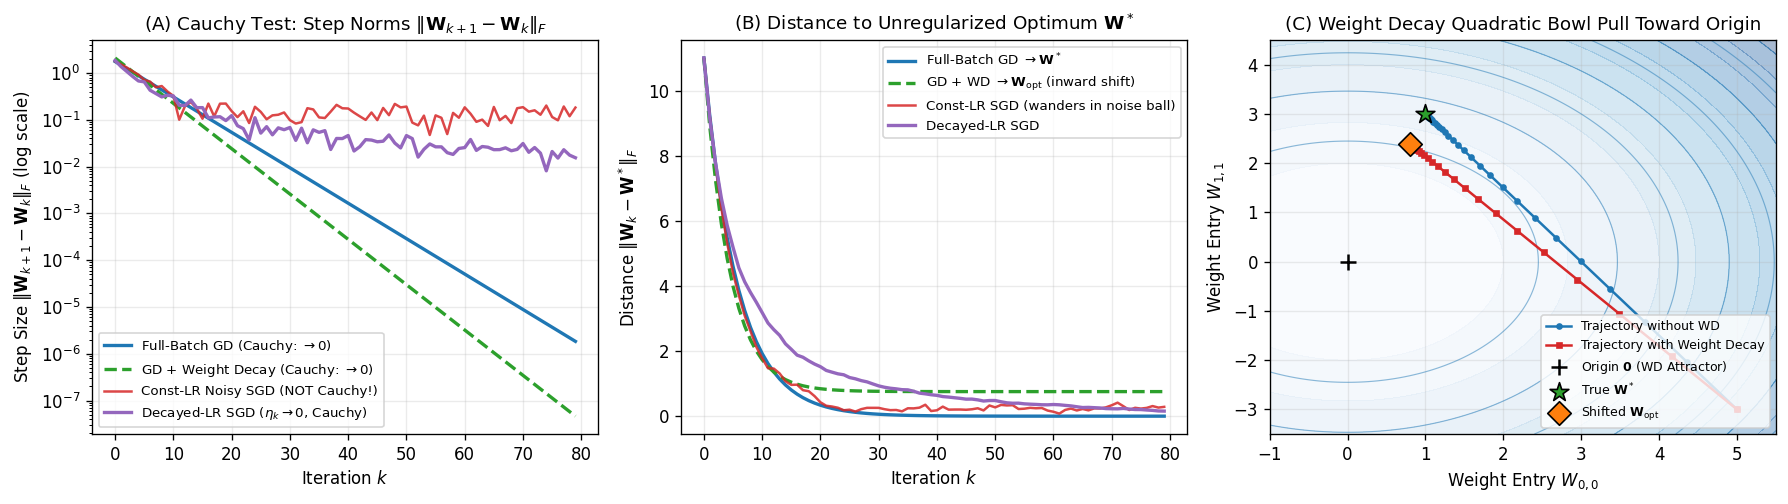

In [9]:
# Reproduce Chapter 1's exact 2x2 Weight Matrix Banach Space trajectories
W_star = np.array([[1.0, -2.0],
                   [0.5,  3.0]])
W_init = np.array([[ 5.0,  5.0],
                   [-4.0, -3.0]])

eta = 0.08
lam_wd = 0.5
steps = 80
W_opt_theoretical = (2.0 / (2.0 + lam_wd)) * W_star

def run_matrix_optimization(mode="clean_gd"):
    W = W_init.copy()
    traj = [W.copy()]
    step_diffs = []
    dist_to_star = []
    losses = []
    for k in range(steps):
        lr = eta / (1.0 + 0.08 * k) if mode == "sgd_decayed" else eta
        grad = 2.0 * (W - W_star)
        if mode in ("sgd_const", "sgd_decayed"):
            grad = grad + np.random.randn(*W.shape) * 0.9  # Minibatch gradient noise
        if mode == "weight_decay":
            W_next = W - lr * grad - lr * lam_wd * W
        else:
            W_next = W - lr * grad
        losses.append(np.linalg.norm(W - W_star, "fro")**2)
        step_diffs.append(np.linalg.norm(W_next - W, "fro"))
        dist_to_star.append(np.linalg.norm(W - W_star, "fro"))
        W = W_next
        traj.append(W.copy())
    return np.array(traj), np.array(losses), np.array(step_diffs), np.array(dist_to_star)

np.random.seed(7)
traj_gd, loss_gd, diff_gd, dist_gd = run_matrix_optimization("clean_gd")
traj_wd, loss_wd, diff_wd, dist_wd = run_matrix_optimization("weight_decay")
traj_noisy, loss_noisy, diff_noisy, dist_noisy = run_matrix_optimization("sgd_const")
traj_decay, loss_decay, diff_decay, dist_decay = run_matrix_optimization("sgd_decayed")

print("Converged W (Standard GD):\n", traj_gd[-1].round(4))
print("Converged W (With Weight Decay lambda=0.5):\n", traj_wd[-1].round(4))
print("Theoretical Shifted Optimum W_opt = (2/(2+lambda))*W^*:\n", W_opt_theoretical.round(4))
print(f"Max error between converged WD matrix and W_opt: {np.max(np.abs(traj_wd[-1] - W_opt_theoretical)):.2e}")

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3))

# Plot A: Consecutive Parameter Updates ||W_{k+1} - W_k||_F (Cauchy Criterion)
ax = axes[0]
ax.plot(diff_gd, lw=2, color="#1f77b4", label="Full-Batch GD (Cauchy: $\\to 0$)")
ax.plot(diff_wd, lw=2, color="#2ca02c", ls="--", label="GD + Weight Decay (Cauchy: $\\to 0$)")
ax.plot(diff_noisy, lw=1.5, color="#d62728", alpha=0.85, label="Const-LR Noisy SGD (NOT Cauchy!)")
ax.plot(diff_decay, lw=2, color="#9467bd", label="Decayed-LR SGD ($\\eta_k \\to 0$, Cauchy)")
ax.set_yscale("log")
ax.set_xlabel("Iteration $k$")
ax.set_ylabel("Step Size $\\|\\mathbf{W}_{k+1} - \\mathbf{W}_k\\|_F$ (log scale)")
ax.set_title("(A) Cauchy Test: Step Norms $\\|\\mathbf{W}_{k+1} - \\mathbf{W}_k\\|_F$")
ax.legend(fontsize=8)

# Plot B: Distance to Optimum ||W_k - W^*||_F
ax = axes[1]
ax.plot(dist_gd, lw=2, color="#1f77b4", label="Full-Batch GD $\\to \\mathbf{W}^*$")
ax.plot(dist_wd, lw=2, color="#2ca02c", ls="--", label="GD + WD $\\to \\mathbf{W}_{\\mathrm{opt}}$ (inward shift)")
ax.plot(dist_noisy, lw=1.5, color="#d62728", alpha=0.85, label="Const-LR SGD (wanders in noise ball)")
ax.plot(dist_decay, lw=2, color="#9467bd", label="Decayed-LR SGD")
ax.set_xlabel("Iteration $k$")
ax.set_ylabel("Distance $\\|\\mathbf{W}_k - \\mathbf{W}^*\\|_F$")
ax.set_title("(B) Distance to Unregularized Optimum $\\mathbf{W}^*$")
ax.legend(fontsize=8)

# Plot C: 2D Slice of Weight Space (W_{0,0}, W_{1,1}) Showing Weight Decay Radial Pull
ax = axes[2]
w00 = np.linspace(-1.0, 5.5, 150)
w11 = np.linspace(-3.5, 4.5, 150)
G00, G11 = np.meshgrid(w00, w11)
pot_bowl = 0.5 * lam_wd * (G00**2 + G11**2)
ax.contourf(G00, G11, pot_bowl, levels=12, cmap="Blues", alpha=0.35)
ax.contour(G00, G11, pot_bowl, levels=8, colors="#1f77b4", linewidths=0.7, alpha=0.5)

ax.plot(traj_gd[:, 0, 0], traj_gd[:, 1, 1], "o-", ms=3, color="#1f77b4", label="Trajectory without WD")
ax.plot(traj_wd[:, 0, 0], traj_wd[:, 1, 1], "s-", ms=3, color="#d62728", label="Trajectory with Weight Decay")
ax.scatter([0], [0], color="k", s=90, marker="+", zorder=6, label="Origin $\\mathbf{0}$ (WD Attractor)")
ax.scatter([W_star[0, 0]], [W_star[1, 1]], color="#2ca02c", s=140, marker="*", edgecolors="k", zorder=6, label="True $\\mathbf{W}^*$")
ax.scatter([W_opt_theoretical[0, 0]], [W_opt_theoretical[1, 1]], color="#ff7f0e", s=100, marker="D", edgecolors="k", zorder=6, label="Shifted $\\mathbf{W}_{\\mathrm{opt}}$")
ax.set_xlabel("Weight Entry $W_{0,0}$")
ax.set_ylabel("Weight Entry $W_{1,1}$")
ax.set_title("(C) Weight Decay Quadratic Bowl Pull Toward Origin")
ax.legend(fontsize=7.5, loc="lower right")

plt.tight_layout()
plt.show()

### 4.3 PyTorch Deep Learning Practical: Weight Decay, $\ell_2$ Regularization & `Adam` vs. `AdamW`

In Section *"Weight decay as a geometric intervention"*, Chapter 1 highlights a crucial distinction in modern deep learning:
- For **SGD**, adding an $\ell_2$ penalty $\frac{\lambda}{2}\|\boldsymbol{\theta}\|_2^2$ to the loss is **mathematically identical** to decoupled weight decay ($\boldsymbol{\theta}_{k+1} = (1 - \eta\lambda)\boldsymbol{\theta}_k - \eta \nabla \mathcal{L}(\boldsymbol{\theta}_k)$).
- For **Adam**, they are **NOT equivalent**!
  - **Adam + Coupled $\ell_2$ Regularization** adds $\lambda \boldsymbol{\theta}_k$ to the gradient *before* dividing by the adaptive second-moment preconditioner $\sqrt{\mathbf{v}_k} + \epsilon$ ($\text{Std-}\ell_2$ geometry). Consequently, parameters with large historical gradients receive **weaker** weight decay than parameters with small gradients—a geometric mismatch!
  - **AdamW (Decoupled Weight Decay)** separates the two geometries: it takes the adaptive $\text{Std-}\ell_2$ step using the data gradient alone, and applies weight decay $-\eta\lambda\boldsymbol{\theta}_k$ directly in Euclidean parameter space.

Let's train a 2-layer Neural Network (MLP) in PyTorch on a small noisy regression dataset where an unregularized network severely overfits, and compare:
1. **Unregularized Adam** ($\lambda = 0$)
2. **SGD + Weight Decay**
3. **Adam + Coupled $\ell_2$ Penalty** (`weight_decay` mixed into gradient)
4. **AdamW + Decoupled Weight Decay**

In [10]:
# Generate a small noisy 1D regression dataset prone to overfitting
torch.manual_seed(42)
np.random.seed(42)

n_train_dl = 22
x_train_dl = np.sort(np.random.uniform(-2.0, 2.0, n_train_dl))
y_true_fn = lambda x: np.sin(1.8 * x) + 0.3 * x
y_train_dl = y_true_fn(x_train_dl) + 0.38 * np.random.randn(n_train_dl)

x_grid_dl = np.linspace(-2.2, 2.2, 200)
y_clean_dl = y_true_fn(x_grid_dl)

X_tr_t = torch.tensor(x_train_dl, dtype=torch.float32).unsqueeze(1)
y_tr_t = torch.tensor(y_train_dl, dtype=torch.float32).unsqueeze(1)
X_grid_t = torch.tensor(x_grid_dl, dtype=torch.float32).unsqueeze(1)

class OverparameterizedMLP(nn.Module):
    def __init__(self, hidden=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(1, hidden),
            nn.Tanh(),
            nn.Linear(hidden, hidden),
            nn.Tanh(),
            nn.Linear(hidden, 1)
        )
    def forward(self, x):
        return self.net(x)

def total_frobenius_norm(model):
    return float(np.sqrt(sum(torch.sum(p.detach()**2).item() for p in model.parameters())))

def train_mlp(mode, epochs=1200):
    torch.manual_seed(10)
    model = OverparameterizedMLP(hidden=64)
    criterion = nn.MSELoss()
    
    if mode == "Adam (No WD)":
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.0)
    elif mode == "SGD + Weight Decay":
        opt = torch.optim.SGD(model.parameters(), lr=0.03, momentum=0.9, weight_decay=0.02)
    elif mode == "Adam + Coupled L2":
        # Standard Adam with L2 penalty added inside gradient
        opt = torch.optim.Adam(model.parameters(), lr=0.01, weight_decay=0.02)
    elif mode == "AdamW (Decoupled WD)":
        # Decoupled weight decay (true Euclidean contraction step -eta * lambda * W)
        opt = torch.optim.AdamW(model.parameters(), lr=0.01, weight_decay=0.8)
    
    val_losses = []
    f_norms = []
    for _ in range(epochs):
        opt.zero_grad()
        pred = model(X_tr_t)
        loss = criterion(pred, y_tr_t)
        loss.backward()
        opt.step()
        
        with torch.no_grad():
            pred_grid = model(X_grid_t).squeeze(1).numpy()
            val_mse = float(np.mean((pred_grid - y_clean_dl) ** 2))
            val_losses.append(val_mse)
            f_norms.append(total_frobenius_norm(model))
            
    with torch.no_grad():
        final_curve = model(X_grid_t).squeeze(1).numpy()
        train_mse = float(criterion(model(X_tr_t), y_tr_t).item())
    return final_curve, train_mse, val_losses[-1], val_losses, f_norms

modes = ["Adam (No WD)", "SGD + Weight Decay", "Adam + Coupled L2", "AdamW (Decoupled WD)"]
results = {}
for m in modes:
    curve, tr_mse, te_mse, v_hist, fn_hist = train_mlp(m)
    results[m] = (curve, tr_mse, te_mse, v_hist, fn_hist)
    print(f"{m:22s} | Train MSE: {tr_mse:.4f} | True-Function MSE: {te_mse:.4f} | Parameter ||W||_F: {fn_hist[-1]:.2f}")

Adam (No WD)           | Train MSE: 0.0042 | True-Function MSE: 0.4024 | Parameter ||W||_F: 22.65
SGD + Weight Decay     | Train MSE: 0.1193 | True-Function MSE: 0.0569 | Parameter ||W||_F: 2.90
Adam + Coupled L2      | Train MSE: 0.1155 | True-Function MSE: 0.0424 | Parameter ||W||_F: 3.05
AdamW (Decoupled WD)   | Train MSE: 0.0811 | True-Function MSE: 0.0843 | Parameter ||W||_F: 9.59


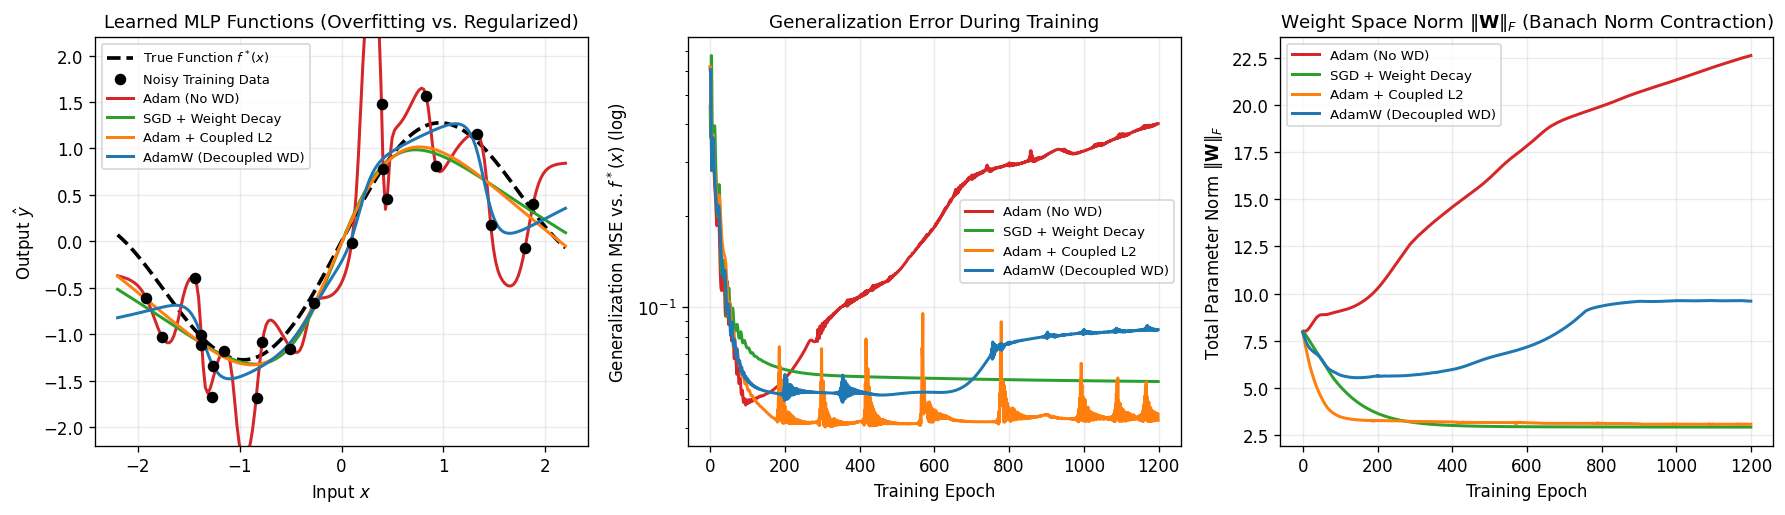

In [11]:
# Visualize the learned functions, generalization error, and Frobenius norm trajectories
fig, axes = plt.subplots(1, 3, figsize=(15, 4.4))
colors_dl = {
    "Adam (No WD)": "#d62728",
    "SGD + Weight Decay": "#2ca02c",
    "Adam + Coupled L2": "#ff7f0e",
    "AdamW (Decoupled WD)": "#1f77b4"
}

# Panel 1: Fitted curves vs True Function
ax = axes[0]
ax.plot(x_grid_dl, y_clean_dl, "k--", lw=2.2, label="True Function $f^*(x)$")
ax.scatter(x_train_dl, y_train_dl, color="k", s=35, zorder=5, label="Noisy Training Data")
for m in modes:
    ax.plot(x_grid_dl, results[m][0], lw=1.8, color=colors_dl[m], label=m)
ax.set_ylim(-2.2, 2.2)
ax.set_xlabel("Input $x$")
ax.set_ylabel("Output $\\hat{y}$")
ax.set_title("Learned MLP Functions (Overfitting vs. Regularized)")
ax.legend(fontsize=7.8, loc="upper left")

# Panel 2: True-Function Generalization MSE over Epochs
ax = axes[1]
for m in modes:
    ax.plot(results[m][3], lw=1.8, color=colors_dl[m], label=m)
ax.set_yscale("log")
ax.set_xlabel("Training Epoch")
ax.set_ylabel("Generalization MSE vs. $f^*(x)$ (log)")
ax.set_title("Generalization Error During Training")
ax.legend(fontsize=8)

# Panel 3: Network Weight Frobenius Norm ||W||_F over Epochs
ax = axes[2]
for m in modes:
    ax.plot(results[m][4], lw=1.8, color=colors_dl[m], label=m)
ax.set_xlabel("Training Epoch")
ax.set_ylabel("Total Parameter Norm $\\|\\mathbf{W}\\|_F$")
ax.set_title("Weight Space Norm $\\|\\mathbf{W}\\|_F$ (Banach Norm Contraction)")
ax.legend(fontsize=8)

plt.tight_layout()
plt.show()

---
## Part 5: Gram–Schmidt Orthonormalization & Scaled Dot-Product Attention in Hilbert Space

### 5.1 Gram–Schmidt Algorithm for Orthonormal Basis Construction

Given linearly independent vectors $\{\mathbf{v}_0, \ldots, \mathbf{v}_{k-1}\} \subset \mathbb{R}^d$, the **Gram–Schmidt algorithm** recursively subtracts projections onto previously constructed unit vectors:
$$\mathbf{u}_j = \mathbf{v}_j - \sum_{i=0}^{j-1} \langle \mathbf{v}_j, \mathbf{q}_i \rangle \mathbf{q}_i, \qquad \mathbf{q}_j = \frac{\mathbf{u}_j}{\|\mathbf{u}_j\|_2}$$
producing an orthonormal basis $Q = [\mathbf{q}_0, \ldots, \mathbf{q}_{k-1}]$ satisfying $Q^\top Q = I_k$.

### 5.2 Transformer Scaled Dot-Product Attention in Hilbert Space

In Section *"Example: Transformer Attention in Hilbert Space"*, token representations $\mathbf{x}_i \in \mathbb{R}^d$ are mapped to queries, keys, and values ($Q = XW_Q, K = XW_K, V = XW_V$), and attention computes:
$$\text{Attention}(Q, K, V) = \underbrace{\text{softmax}\!\left(\frac{QK^\top}{\sqrt{d_k}}\right)}_{A \text{ (row-stochastic)}} V$$
Why do we divide the inner products $\langle \mathbf{q}_i, \mathbf{k}_j \rangle$ by $\sqrt{d_k}$?
- If components of $\mathbf{q}, \mathbf{k} \in \mathbb{R}^{d_k}$ have zero mean and unit variance, then $\operatorname{Var}(\mathbf{q}^\top \mathbf{k}) = d_k$, so $\|\mathbf{q}^\top \mathbf{k}\| \sim \mathcal{O}(\sqrt{d_k})$.
- For large $d_k$, unscaled dot products push softmax into saturation (one weight $\approx 1$, all others $\approx 0$), causing **vanishing softmax gradients**. Dividing by $\sqrt{d_k}$ restores unit variance!

Gram-Schmidt Orthonormal Basis Q (4x3):
 [[ 0.8165 -0.255  -0.4809]
 [ 0.4082  0.8288  0.3306]
 [ 0.     -0.3825  0.5109]
 [ 0.4082 -0.3188  0.6312]]
Verification Q^T Q == I_3:
 [[ 1. -0. -0.]
 [-0.  1.  0.]
 [-0.  0.  1.]]


<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\l'
<>:59: SyntaxWarning: invalid escape sequence '\l'
<>:67: SyntaxWarning: invalid escape sequence '\l'
/tmp/ipykernel_1225980/465565609.py:59: SyntaxWarning: invalid escape sequence '\l'
  axes[0].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
/tmp/ipykernel_1225980/465565609.py:67: SyntaxWarning: invalid escape sequence '\l'
  axes[1].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")


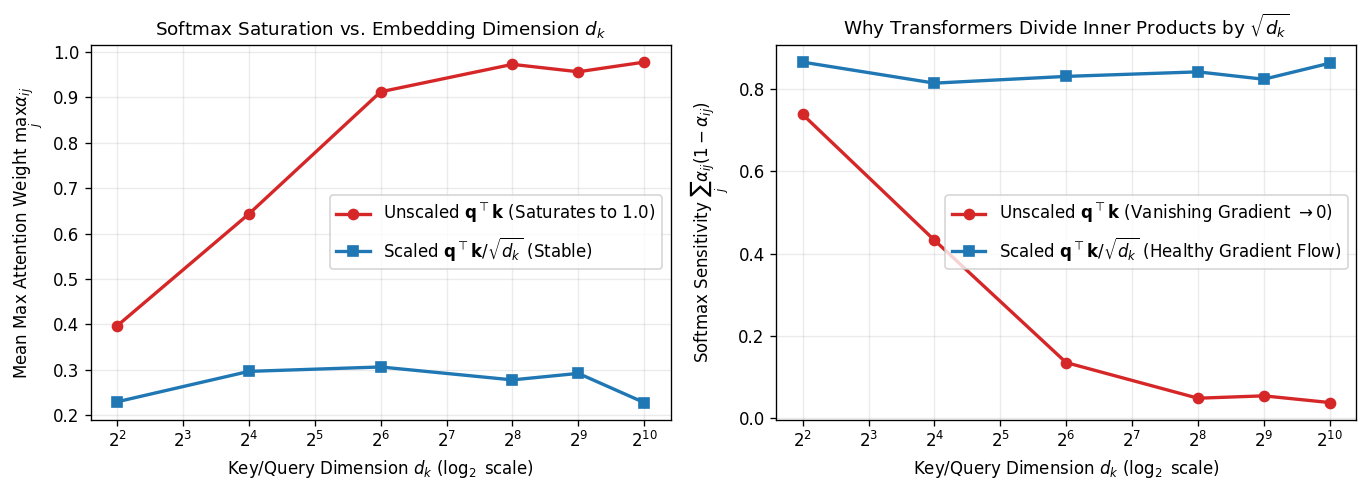

In [12]:
# 1. Gram-Schmidt Orthonormalization From Scratch
def gram_schmidt(V):
    # Orthonormalize columns of V (d x k) using Gram-Schmidt
    d, k = V.shape
    Q = np.zeros((d, k))
    for j in range(k):
        u = V[:, j].copy()
        for i in range(j):
            u -= np.dot(V[:, j], Q[:, i]) * Q[:, i]
        norm_u = np.linalg.norm(u)
        if norm_u < 1e-12:
            raise ValueError(f"Column {j} is linearly dependent on previous columns.")
        Q[:, j] = u / norm_u
    return Q

V_basis = np.array([[2.0,  1.0, 0.0],
                    [1.0,  3.0, 1.0],
                    [0.0, -1.0, 2.0],
                    [1.0,  0.0, 3.0]])
Q_ortho = gram_schmidt(V_basis)
print("Gram-Schmidt Orthonormal Basis Q (4x3):\n", Q_ortho.round(4))
print("Verification Q^T Q == I_3:\n", (Q_ortho.T @ Q_ortho).round(10))

# 2. Scaled Dot-Product Attention & Softmax Gradient Norm vs Dimension d_k
def softmax_rows(S):
    S_shift = S - np.max(S, axis=-1, keepdims=True)
    exp_S = np.exp(S_shift)
    return exp_S / np.sum(exp_S, axis=-1, keepdims=True)

dims = [4, 16, 64, 256, 512, 1024]
unscaled_max_prob, scaled_max_prob = [], []
unscaled_grad_norm, scaled_grad_norm = [], []

np.random.seed(42)
n_tokens = 12
for d_k in dims:
    Q_mat = np.random.randn(n_tokens, d_k)
    K_mat = np.random.randn(n_tokens, d_k)
    
    S_raw = Q_mat @ K_mat.T
    S_scaled = S_raw / np.sqrt(d_k)
    
    A_raw = softmax_rows(S_raw)
    A_scaled = softmax_rows(S_scaled)
    
    # Average max attention weight per row (1.0 means complete one-hot saturation)
    unscaled_max_prob.append(np.mean(np.max(A_raw, axis=-1)))
    scaled_max_prob.append(np.mean(np.max(A_scaled, axis=-1)))
    
    # Softmax Jacobian Frobenius norm: sum_j p_j (1 - p_j) measures gradient sensitivity
    unscaled_grad_norm.append(np.mean(np.sum(A_raw * (1.0 - A_raw), axis=-1)))
    scaled_grad_norm.append(np.mean(np.sum(A_scaled * (1.0 - A_scaled), axis=-1)))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.2))

axes[0].plot(dims, unscaled_max_prob, "o-", color="#d62728", lw=2, label="Unscaled $\\mathbf{q}^\\top\\mathbf{k}$ (Saturates to 1.0)")
axes[0].plot(dims, scaled_max_prob, "s-", color="#1f77b4", lw=2, label="Scaled $\\mathbf{q}^\\top\\mathbf{k} / \\sqrt{d_k}$ (Stable)")
axes[0].set_xscale("log", base=2)
axes[0].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
axes[0].set_ylabel("Mean Max Attention Weight $\\max_j \\alpha_{ij}$")
axes[0].set_title("Softmax Saturation vs. Embedding Dimension $d_k$")
axes[0].legend()

axes[1].plot(dims, unscaled_grad_norm, "o-", color="#d62728", lw=2, label="Unscaled $\\mathbf{q}^\\top\\mathbf{k}$ (Vanishing Gradient $\\to 0$)")
axes[1].plot(dims, scaled_grad_norm, "s-", color="#1f77b4", lw=2, label="Scaled $\\mathbf{q}^\\top\\mathbf{k} / \\sqrt{d_k}$ (Healthy Gradient Flow)")
axes[1].set_xscale("log", base=2)
axes[1].set_xlabel("Key/Query Dimension $d_k$ ($\log_2$ scale)")
axes[1].set_ylabel("Softmax Sensitivity $\\sum_j \\alpha_{ij}(1 - \\alpha_{ij})$")
axes[1].set_title("Why Transformers Divide Inner Products by $\\sqrt{d_k}$")
axes[1].legend()

plt.tight_layout()
plt.show()